<a href="https://colab.research.google.com/github/haidermalik68/Ai-image-checker/blob/main/00_Real_vs_AI_project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##0.Setup

This installs the Hugging Face library and loads the tools we use: one for the dataset, one for images, one for folders, and one for tables.



This opens a stream to the dataset online. Nothing is downloaded yet. It also prints the column names, which should be Caption, Image, Label_A, Label_B.

In [3]:
!pip install -q datasets
from datasets import load_dataset
from PIL import Image
from pathlib import Path
import pandas as pd

ds = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset",
                  split="train", streaming=True)
print(ds.features)

{'Caption': Value('string'), 'Image': Image(mode=None, decode=True), 'Label_A': Value('int32'), 'Label_B': Value('int32')}


##01.Names and targets

names turns the dataset’s numbers into readable names. how_many is how many images we want from each source. saved counts how many we’ve saved so far. records is an empty list where we’ll write one line of facts per image.

In [4]:
names = {0: "real", 1: "sd21", 2: "sdxl", 3: "sd3", 4: "dalle3", 5: "midjourney"}
how_many = {0: 6000, 1: 3000, 2: 3000, 3: 3000, 4: 3000, 5: 3000}
saved = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0}
records = []


##03. Download, crop, resize, save (the long one)

For each image in the stream, it checks whether we still need images from that source. If so, it does these steps:

1. Remembers the original format and size.
2. Cuts out the largest centered square, so nothing gets stretched.  Real photos are rectangles and the fakes are already squares, so this treats them the same way.
3. Shrinks the square to 256×256.
4. Saves it as a JPEG in a folder named after its source.
5. Writes one line in records.

In [5]:
for row in ds.shuffle(seed=42, buffer_size=5000):
    k = row["Label_B"]

    if saved[k] >= how_many[k]:
        continue

    image = row["Image"]
    format_name = image.format
    size = image.size
    image = image.convert("RGB")

    w, h = size
    side = min(w, h)
    left = (w - side) // 2
    top = (h - side) // 2
    square = image.crop((left, top, left + side, top + side))
    small = square.resize((256, 256))

    folder = Path("/content/data/" + names[k])
    folder.mkdir(parents=True, exist_ok=True)
    file_path = folder / (str(saved[k]) + ".jpg")
    small.save(file_path, quality=95)

    records.append({
        "file": str(file_path),
        "generator": names[k],
        "label": 0 if k == 0 else 1,
        "orig_format": format_name,
        "orig_size": size,
    })
    saved[k] = saved[k] + 1

    total = sum(saved.values())
    if total % 1000 == 0:
        print(total, "images saved")
    if total == sum(how_many.values()):
        break

1000 images saved
2000 images saved
3000 images saved
4000 images saved
5000 images saved
6000 images saved
7000 images saved
8000 images saved
9000 images saved
10000 images saved
11000 images saved
12000 images saved
13000 images saved
14000 images saved
15000 images saved
16000 images saved
17000 images saved
18000 images saved
19000 images saved
20000 images saved
21000 images saved


##04. Save the table and check it

This turns the records into a table, saves it as meta.csv, and prints two checks: how many images each source has, and their original file formats. You should see 6,000 real and 3,000 for each generator.

In [6]:
table = pd.DataFrame(records)
table.to_csv("/content/meta.csv", index=False)

print(table["generator"].value_counts())
print(table.groupby("generator")["orig_format"].value_counts())

generator
real          6000
sdxl          3000
midjourney    3000
dalle3        3000
sd3           3000
sd21          3000
Name: count, dtype: int64
generator   orig_format
dalle3      JPEG           3000
midjourney  JPEG           3000
real        JPEG           6000
sd21        JPEG           3000
sd3         JPEG           3000
sdxl        JPEG           3000
Name: count, dtype: int64


##05. Back up to Drive

This is the most important cell for avoiding a repeat. It plugs your Google Drive in (a popup will ask for permission), makes a project folder, and puts the table and a zip of all the images there. Check Drive afterward and confirm data.zip and meta.csv are in ai_image_checker.

In [7]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/drive/MyDrive/ai_image_checker
!cp /content/meta.csv /content/drive/MyDrive/ai_image_checker/
!cd /content && zip -qr /content/drive/MyDrive/ai_image_checker/data.zip data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
for name in ["real", "sd21", "sdxl", "sd3", "dalle3", "midjourney"]:
    part = table[table["generator"] == name]
    print(name)
    print(part["orig_size"].value_counts().head(3))


real
orig_size
(640, 480)    1348
(640, 427)     704
(480, 640)     494
Name: count, dtype: int64
sd21
orig_size
(768, 768)    3000
Name: count, dtype: int64
sdxl
orig_size
(1024, 1024)    3000
Name: count, dtype: int64
sd3
orig_size
(1024, 1024)    3000
Name: count, dtype: int64
dalle3
orig_size
(270, 270)    2984
(351, 351)      16
Name: count, dtype: int64
midjourney
orig_size
(436, 436)    2999
(630, 630)       1
Name: count, dtype: int64


##06. Look at the images

This shows a grid with 4 images from each source. Use it to check that the real photos look natural and not stretched.

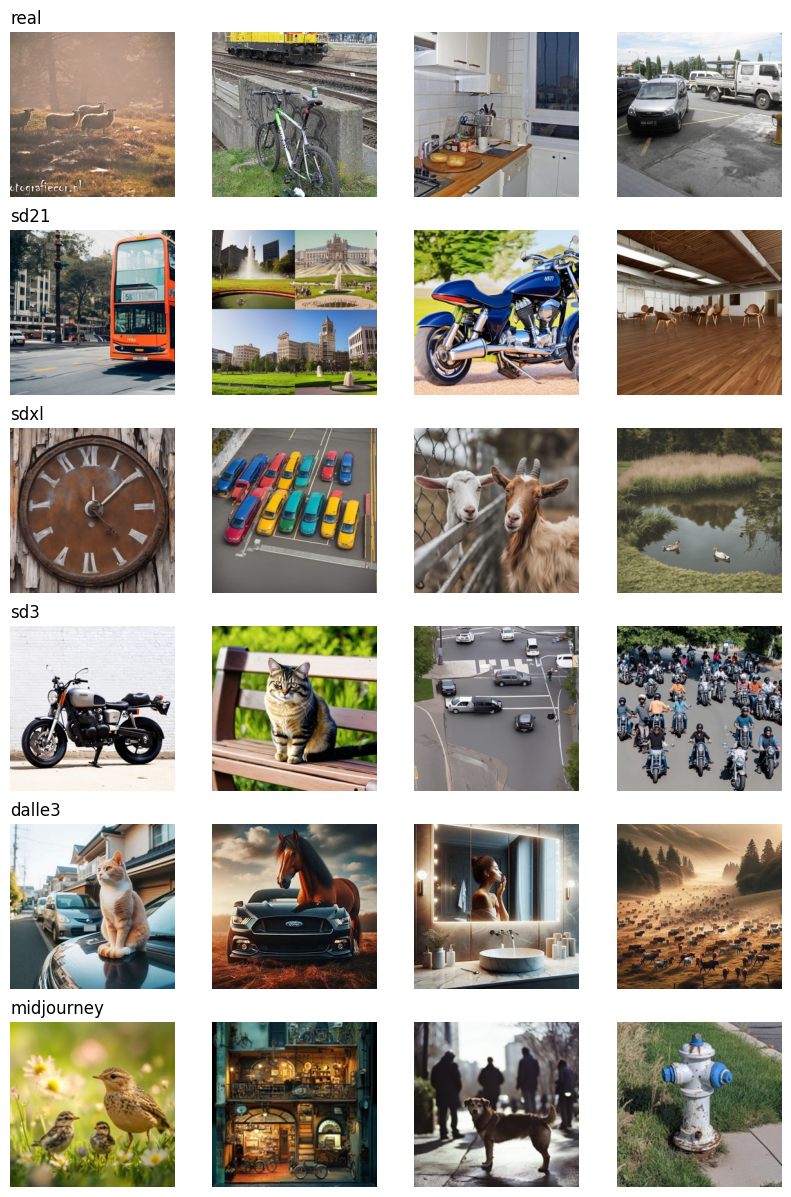

In [9]:
import matplotlib.pyplot as plt

sources = ["real", "sd21", "sdxl", "sd3", "dalle3", "midjourney"]
fig, axes = plt.subplots(6, 4, figsize=(10, 15))

for r in range(6):
    for c in range(4):
        path = "/content/data/" + sources[r] + "/" + str(c) + ".jpg"
        axes[r][c].imshow(Image.open(path))
        axes[r][c].axis("off")
    axes[r][0].set_title(sources[r], loc="left")

plt.show()

##Load the table
This reads the inventory file we saved earlier ...



In [23]:
import pandas as pd
table=pd.read_csv("/content/meta.csv")
print(len(table))

21000


In [24]:
## helper function to pick images
def pick(name,start,end):
  part = table[table["generator"] == name]
  part = part.sample(frac=1,random_state=42)
  return part.iloc[start:end]

##8.Build the three sets

Each line combines slices from different sources. The ranges are chosen so no image appears twice. For example, real images use 0-3600 for training, 3600-4200 for validation, and 4200-6000 for testing.

In [31]:
train = pd.concat([
    pick("real", 0, 3600),
    pick("sd21", 0, 1800),
    pick("sdxl",0,1800),
    ])
val = pd.concat([
    pick("real",  3600,4200),
    pick("sd21",  1800,2100),
    pick("sdxl",1800,2100),
    ])
test = pd.concat([
    pick("real",4200,6000),
    pick("sd21",2100,3000),
    pick("sdxl",2100,3000),
    pick("dalle3",0,3000),
    pick("midjourney",0,3000),
    pick("sd3",0,3000),
    ])

In [32]:
print(len(train),len(test),len(val))
print(train["generator"].value_counts())
print(val["generator"].value_counts())
print(test["generator"].value_counts())

##check for duplicates if any
print(len(set(train["file"])&set(val["file"])))
print(len(set(train["file"])&set(test["file"])))
print(len(set(val["file"])&set(test["file"])))

7200 12600 1200
generator
real    3600
sd21    1800
sdxl    1800
Name: count, dtype: int64
generator
real    600
sd21    300
sdxl    300
Name: count, dtype: int64
generator
midjourney    3000
dalle3        3000
sd3           3000
real          1800
sd21           900
sdxl           900
Name: count, dtype: int64
0
0
0


In [33]:
## save and backup sets
train.to_csv("/content/train.csv", index=False)
val.to_csv("/content/val.csv", index=False)
test.to_csv("/content/test.csv", index=False)

!cp /content/train.csv /content/val.csv /content/test.csv /content/drive/MyDrive/ai_image_checker/